# Part 4: Evaluation and Analysis

This notebook evaluates the retrieval methods developed in Part 3 using the official relevance judgments. All results are loaded from previously saved experiment files.

### 4.1 Evaluation Metrics

Two query types are evaluated:

- **Known-item queries:** MRR@10, Success@1, Success@10, and Recall@100.
- **Topic queries:** P@10, P@100, and MAP@100.

The metrics were implemented independently and validated against `pytrec_eval` using the BM25 runs. The largest per-query absolute difference is reported for each test set.

In [5]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path(r"C:\Projects\IR\CS533_HW1")
DATA = ROOT.parent / "data"

PART3 = DATA / "part3_results"
PART4 = DATA / "part4_results"
OFFICIAL = DATA / "nyt-tc-2026"

print("Part 4 results available:", PART4.exists())

Part 4 results available: True


In [6]:
validation_path = PART4 / "bm25_validation_summary.json"

with validation_path.open(encoding="utf-8") as f:
    validation = json.load(f)

print("Validation summary:")
print(json.dumps(validation, indent=2))

Validation summary:
{
  "part": "4.1",
  "method": "BM25",
  "independent_evaluator": "pytrec_eval (Terrier fork)",
  "independent_evaluator_version": "0.5.11",
  "all_passed": true,
  "tolerance": 1e-12,
  "test_sets": [
    {
      "test_set": "KI1",
      "collection": "C1",
      "query_type": "known_item",
      "queries": 1000,
      "means": {
        "MRR@10": 0.8293480158730159,
        "Success@1": 0.758,
        "Success@10": 0.935,
        "Recall@100": 0.971
      },
      "relevant_documents_per_query": {
        "minimum": 1,
        "maximum": 1
      },
      "missing_ranking_queries": [],
      "source_run_validation": {
        "rows": 103200,
        "queries_with_results": 1032,
        "missing_queries": [],
        "queries_with_fewer_than_100_results": 0
      },
      "validation": {
        "MRR@10": {
          "queries": 1000,
          "external_metric": "recip_rank",
          "native_definition_matches": true,
          "largest_native_per_query_absolute_

#### 4.1 Key Findings

The independently implemented evaluation metrics were compared with `pytrec_eval` on the BM25 retrieval runs.

Across all four test sets, the largest absolute per-query difference was approximately **5.55 × 10⁻¹⁶**, well below the validation tolerance of **10⁻¹²**. Known-item metrics matched exactly.

These results confirm that the custom metric calculations agree with the reference implementation to floating-point precision.

### 4.2 Main Retrieval Results

Fifteen retrieval methods were evaluated on four test sets: KI1/C1, KI2/C2, Topics/C1, and Topics/C2.

The methods include TF-IDF, BM25, four dense models (M1, M2, M2s, GN), three query expansion models, three linear hybrids, and three RRF hybrids.

Known-item retrieval is evaluated using MRR@10, Success@1, Success@10, and Recall@100. Topic retrieval is evaluated using P@10, P@100, and MAP@100.

Statistical significance against BM25 was evaluated using 10,000 paired randomization trials, with p < 0.05. The primary metrics are MRR@10 for known-item queries and MAP@100 for topic queries. QE and linear-hybrid parameters were selected on P1 and kept fixed for P2.

In [7]:
# Load saved Part 4.2 evaluation results.

files = {
    "KI1 / C1": "part42_ki1_c1.csv",
    "KI2 / C2": "part42_ki2_c2.csv",
    "Topics / C1": "part42_topics_c1.csv",
    "Topics / C2": "part42_topics_c2.csv",
}

tables = {
    name: pd.read_csv(PART4 / filename)
    for name, filename in files.items()
}

for name, df in tables.items():
    print(f"\n{name} — {len(df)} retrieval methods")

    metrics = (
        ["MRR@10", "Success@1", "Success@10", "Recall@100"]
        if name.startswith("KI")
        else ["P@10", "P@100", "MAP@100"]
    )

    columns = ["method"] + metrics + ["marker"]

    display(df[columns].round(4))


KI1 / C1 — 15 retrieval methods


,method,MRR@10,Success@1,Success@10,Recall@100,marker
0,TF-IDF,0.7528,0.657,0.907,0.967,SIG-
1,BM25,0.8293,0.758,0.935,0.971,BM25
2,Dense M1,0.5667,0.481,0.730,0.881,SIG-
3,Dense M2,0.5734,0.496,0.730,0.879,SIG-
4,Dense M2s,0.5366,0.458,0.694,0.845,SIG-
5,Dense GN,0.5636,0.483,0.728,0.872,SIG-
6,QE M1,0.8281,0.756,0.933,0.972,NaN
7,QE M2,0.8284,0.756,0.931,0.973,NaN
8,QE GN,0.8315,0.762,0.934,0.971,NaN
9,Linear hybrid M1,0.8293,0.758,0.935,0.971,NaN



KI2 / C2 — 15 retrieval methods


,method,MRR@10,Success@1,Success@10,Recall@100,marker
0,TF-IDF,0.6236,0.536,0.801,0.932,SIG-
1,BM25,0.6855,0.610,0.839,0.939,BM25
2,Dense M1,0.4060,0.326,0.593,0.805,SIG-
3,Dense M2,0.4360,0.351,0.623,0.843,SIG-
4,Dense M2s,0.4186,0.337,0.600,0.821,SIG-
5,Dense GN,0.3944,0.325,0.548,0.733,SIG-
6,QE M1,0.6704,0.597,0.823,0.938,SIG-
7,QE M2,0.6534,0.575,0.811,0.939,SIG-
8,QE GN,0.6849,0.607,0.841,0.943,NaN
9,Linear hybrid M1,0.6855,0.610,0.839,0.939,NaN



Topics / C1 — 15 retrieval methods


,method,P@10,P@100,MAP@100,marker
0,TF-IDF,0.6156,0.6003,0.4216,NaN
1,BM25,0.6125,0.6050,0.4228,BM25
2,Dense M1,0.6812,0.7022,0.5597,SIG+
3,Dense M2,0.6656,0.6891,0.5473,SIG+
4,Dense M2s,0.7031,0.6919,0.5396,SIG+
5,Dense GN,0.6906,0.6119,0.4576,NaN
6,QE M1,0.7406,0.6850,0.5554,SIG+
7,QE M2,0.7094,0.6800,0.5334,SIG+
8,QE GN,0.6000,0.6191,0.4309,NaN
9,Linear hybrid M1,0.6812,0.7022,0.5597,SIG+



Topics / C2 — 15 retrieval methods


,method,P@10,P@100,MAP@100,marker
0,TF-IDF,0.7062,0.6766,0.5236,NaN
1,BM25,0.7250,0.6809,0.5226,BM25
2,Dense M1,0.7781,0.7603,0.6403,SIG+
3,Dense M2,0.7562,0.7325,0.6233,SIG+
4,Dense M2s,0.7625,0.7475,0.6267,SIG+
5,Dense GN,0.6375,0.6441,0.4812,NaN
6,QE M1,0.7250,0.7259,0.6022,NaN
7,QE M2,0.8094,0.7472,0.6447,SIG+
8,QE GN,0.6469,0.6738,0.5008,NaN
9,Linear hybrid M1,0.7781,0.7603,0.6403,SIG+


In [8]:
# Summarize significance tests against BM25.

summary_path = PART4 / "part42_summary.json"

with summary_path.open(encoding="utf-8") as f:
    results_summary = json.load(f)

print("Part 4.2 complete:",
      results_summary["all_complete"])

print("Significant improvements over BM25:",
      len(results_summary["significant_improvements_vs_BM25"]))

print("Significant declines versus BM25:",
      len(results_summary["significant_declines_vs_BM25"]))

print("\nBest method by primary metric:")

for name, df in tables.items():
    metric = "MRR@10" if name.startswith("KI") else "MAP@100"

    best = df.loc[df[metric].idxmax()]

    print(
        f"{name}: {best['method']} "
        f"({metric} = {best[metric]:.4f})"
    )

Part 4.2 complete: True
Significant improvements over BM25: 18
Significant declines versus BM25: 18

Best method by primary metric:
KI1 / C1: QE GN (MRR@10 = 0.8315)
KI2 / C2: BM25 (MRR@10 = 0.6855)
Topics / C1: Dense M1 (MAP@100 = 0.5597)
Topics / C2: QE M2 (MAP@100 = 0.6447)


#### 4.2 Key Findings

BM25 performed strongly on known-item retrieval, where identifying the exact target article is the main objective. Dense retrieval was generally less effective for these queries.

For topic retrieval, embedding-based methods performed better. Dense retrieval improved MAP@100 over BM25, showing the benefit of semantic similarity for broader information needs.

Query expansion and hybrid retrieval produced mixed results. Their effectiveness depended on the query type, embedding model, and selected parameters.

Significance markers indicate whether a method performed significantly better (SIG+) or worse (SIG−) than BM25 using paired randomization tests.


P1 — Known-item (MRR@10)


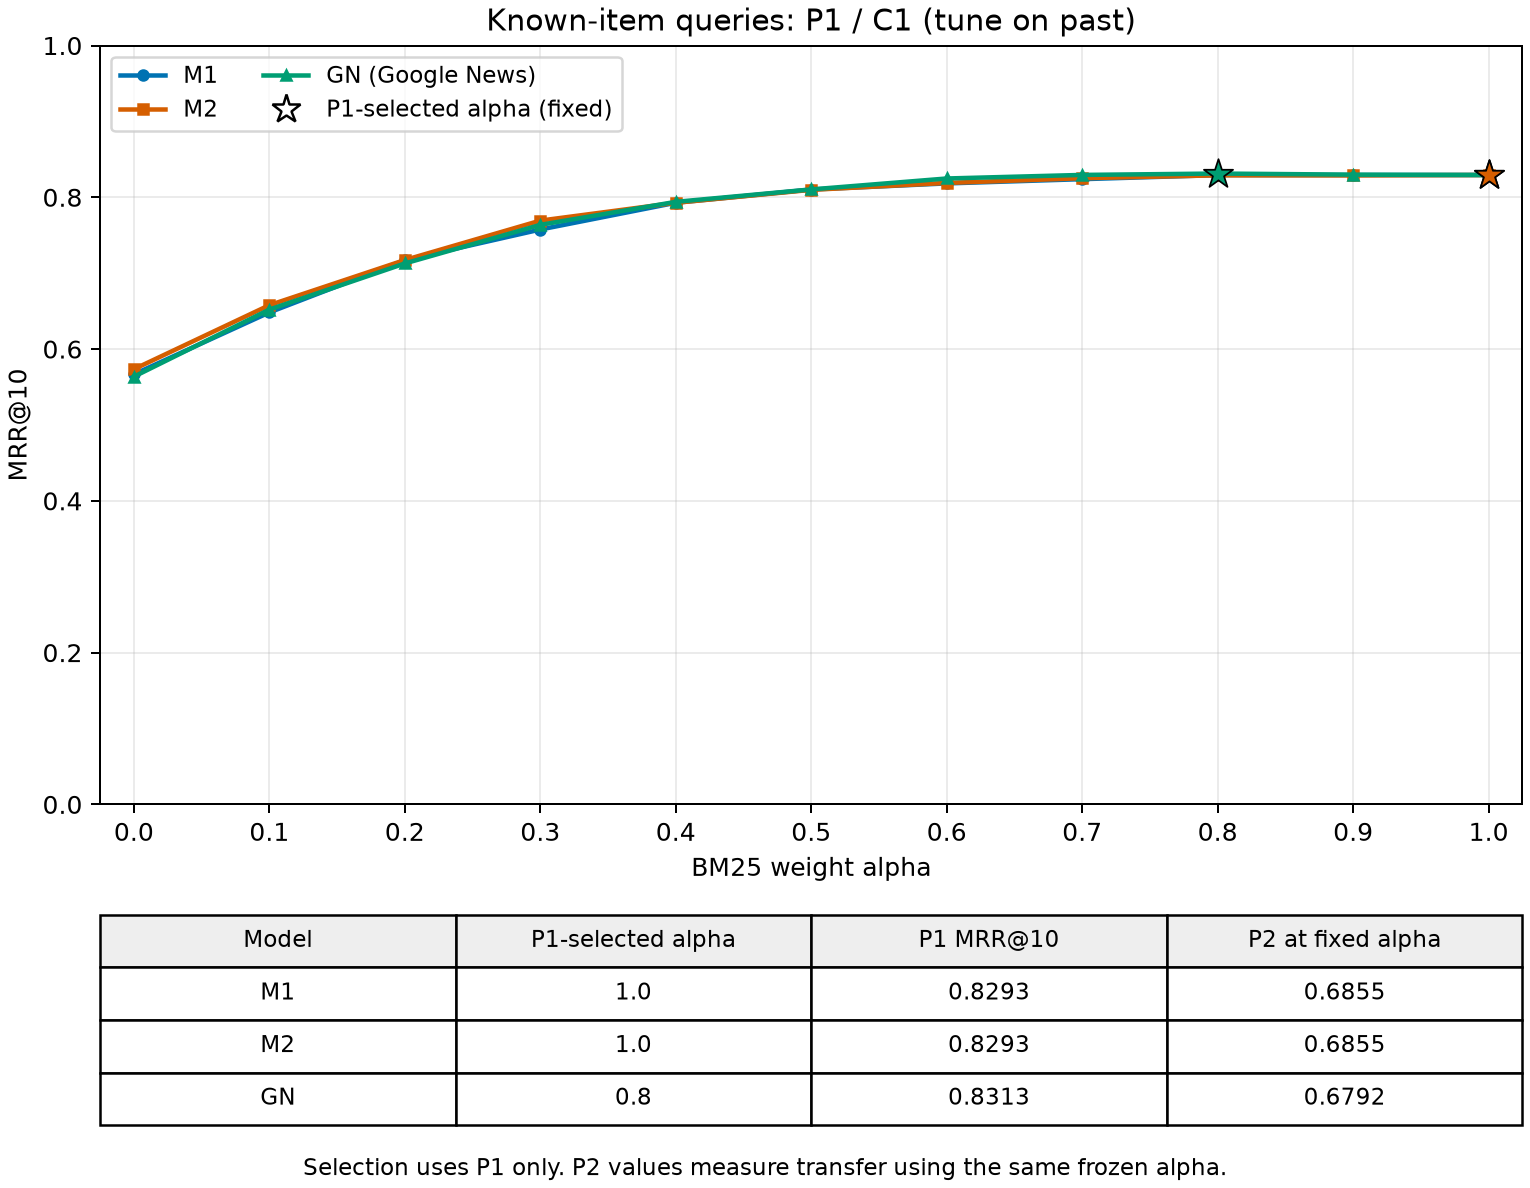


P2 — Known-item (MRR@10)


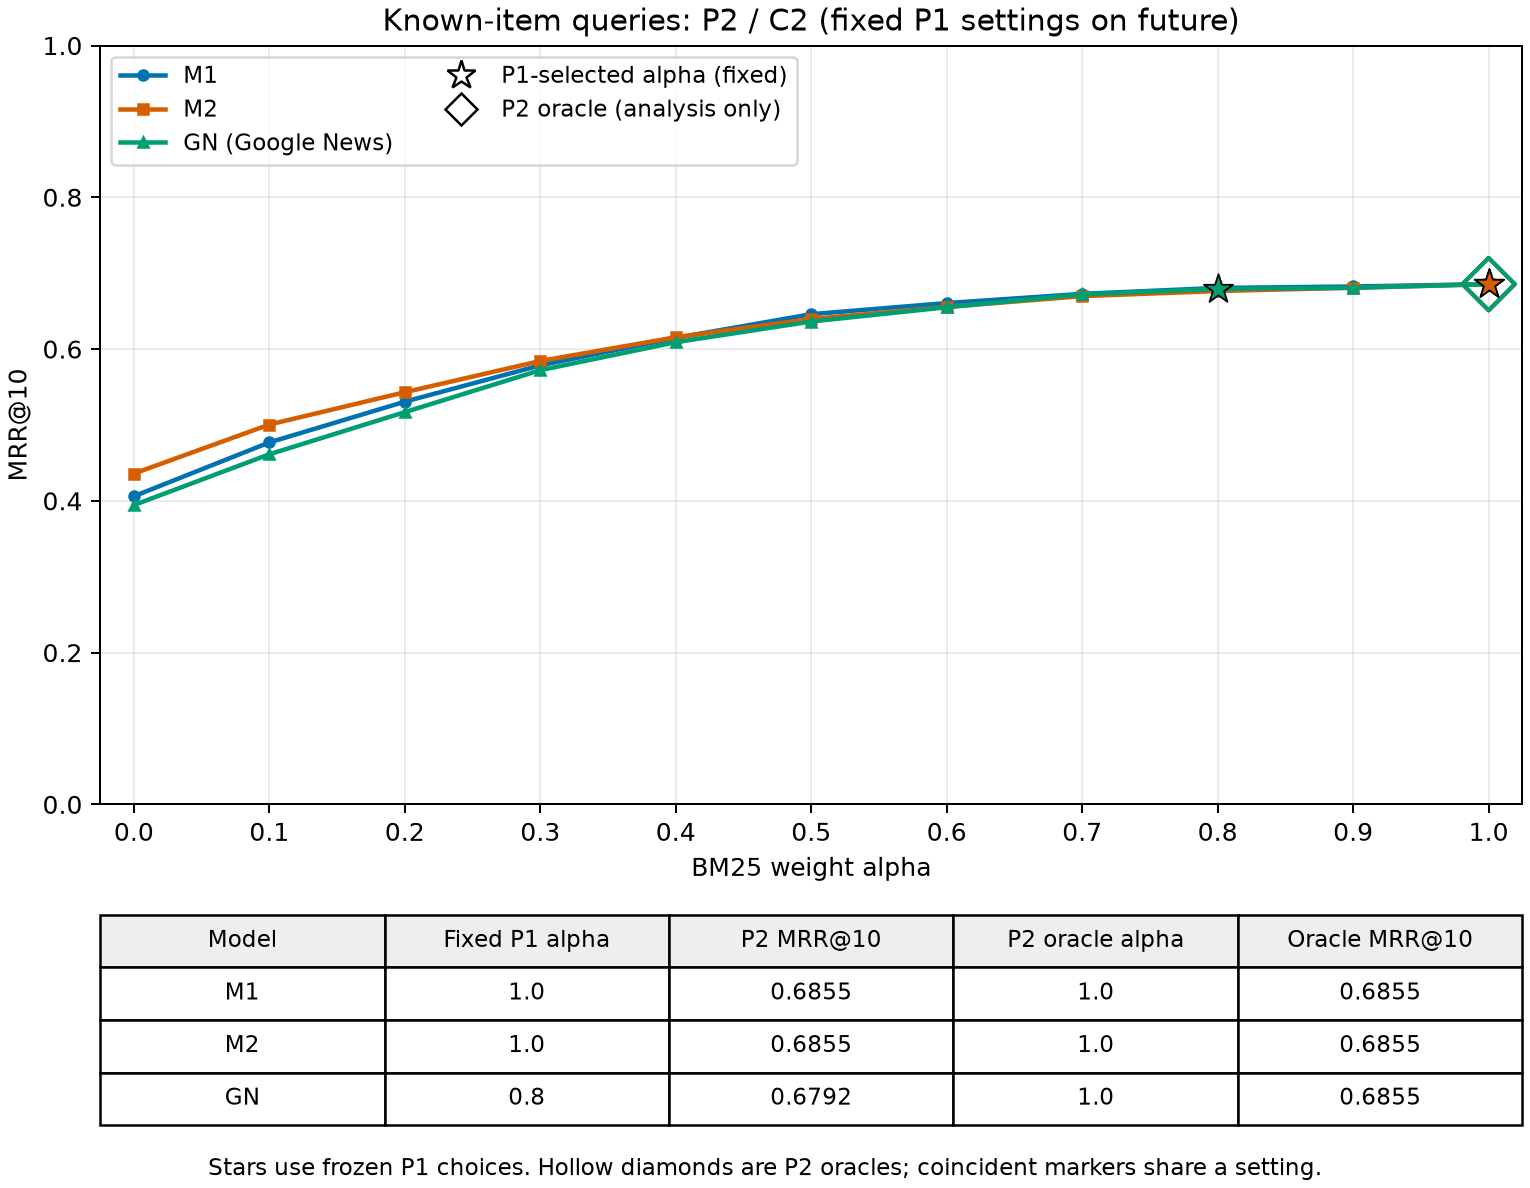


P1 — Topics (MAP@100)


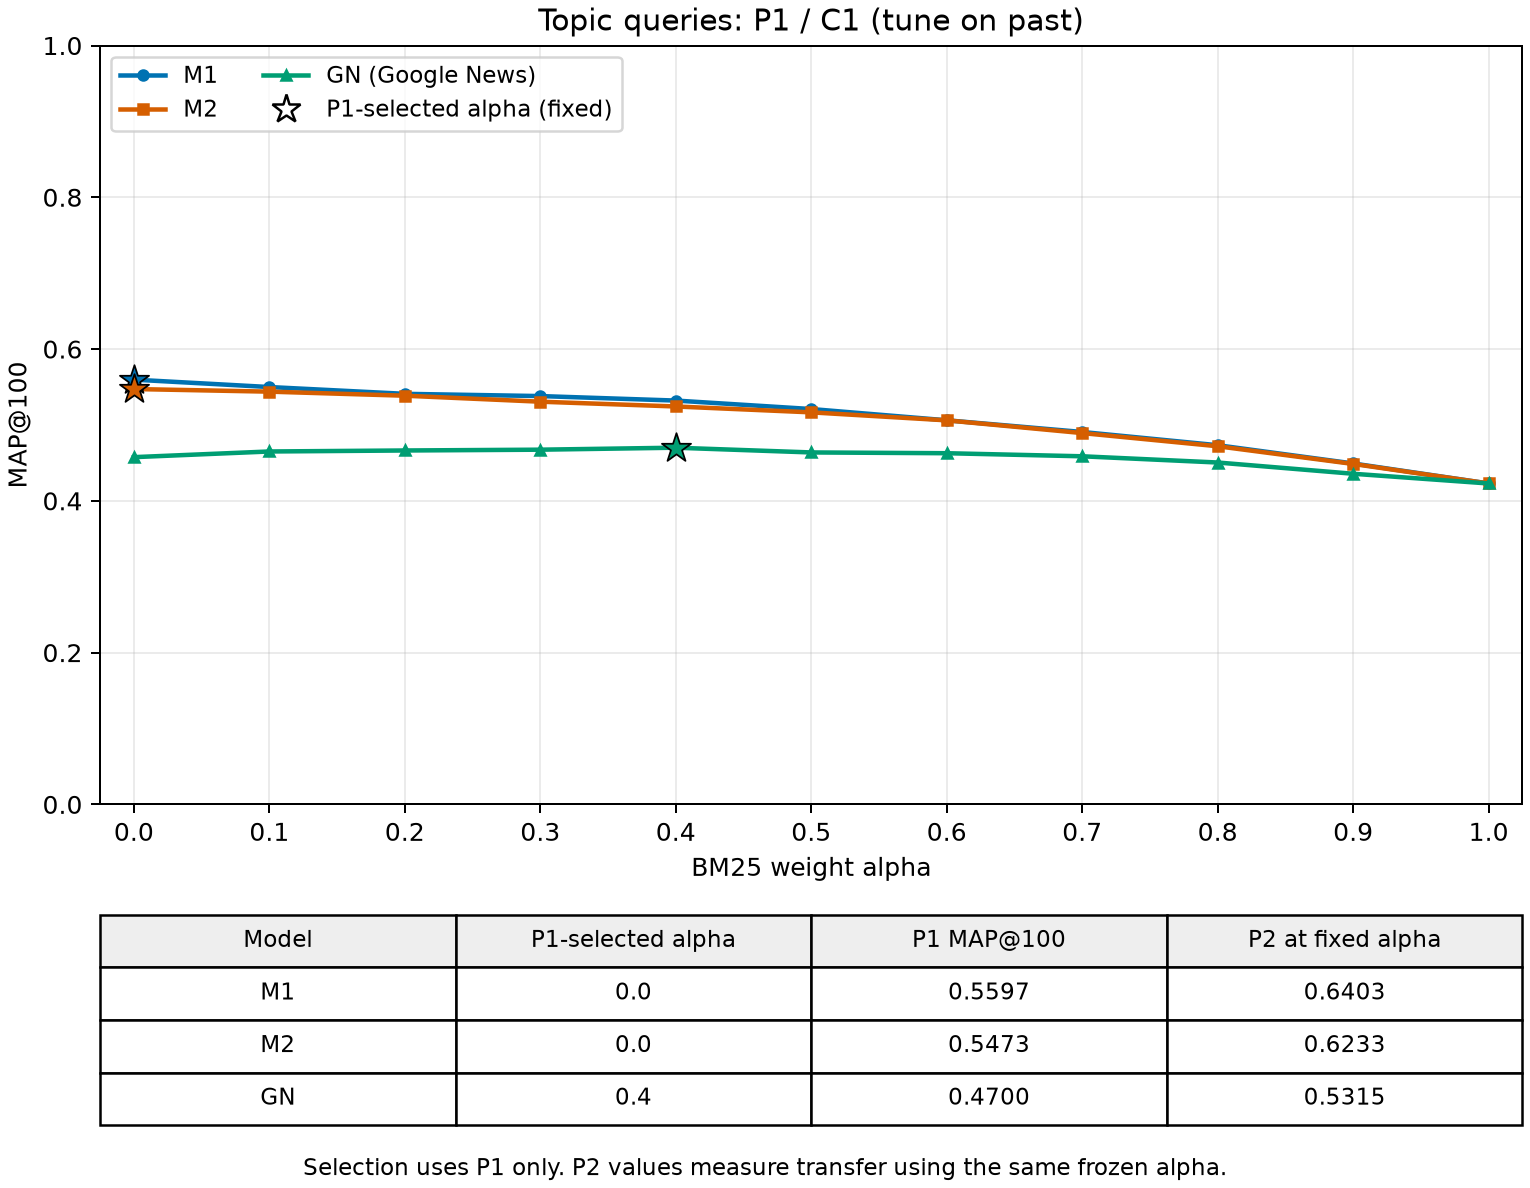


P2 — Topics (MAP@100)


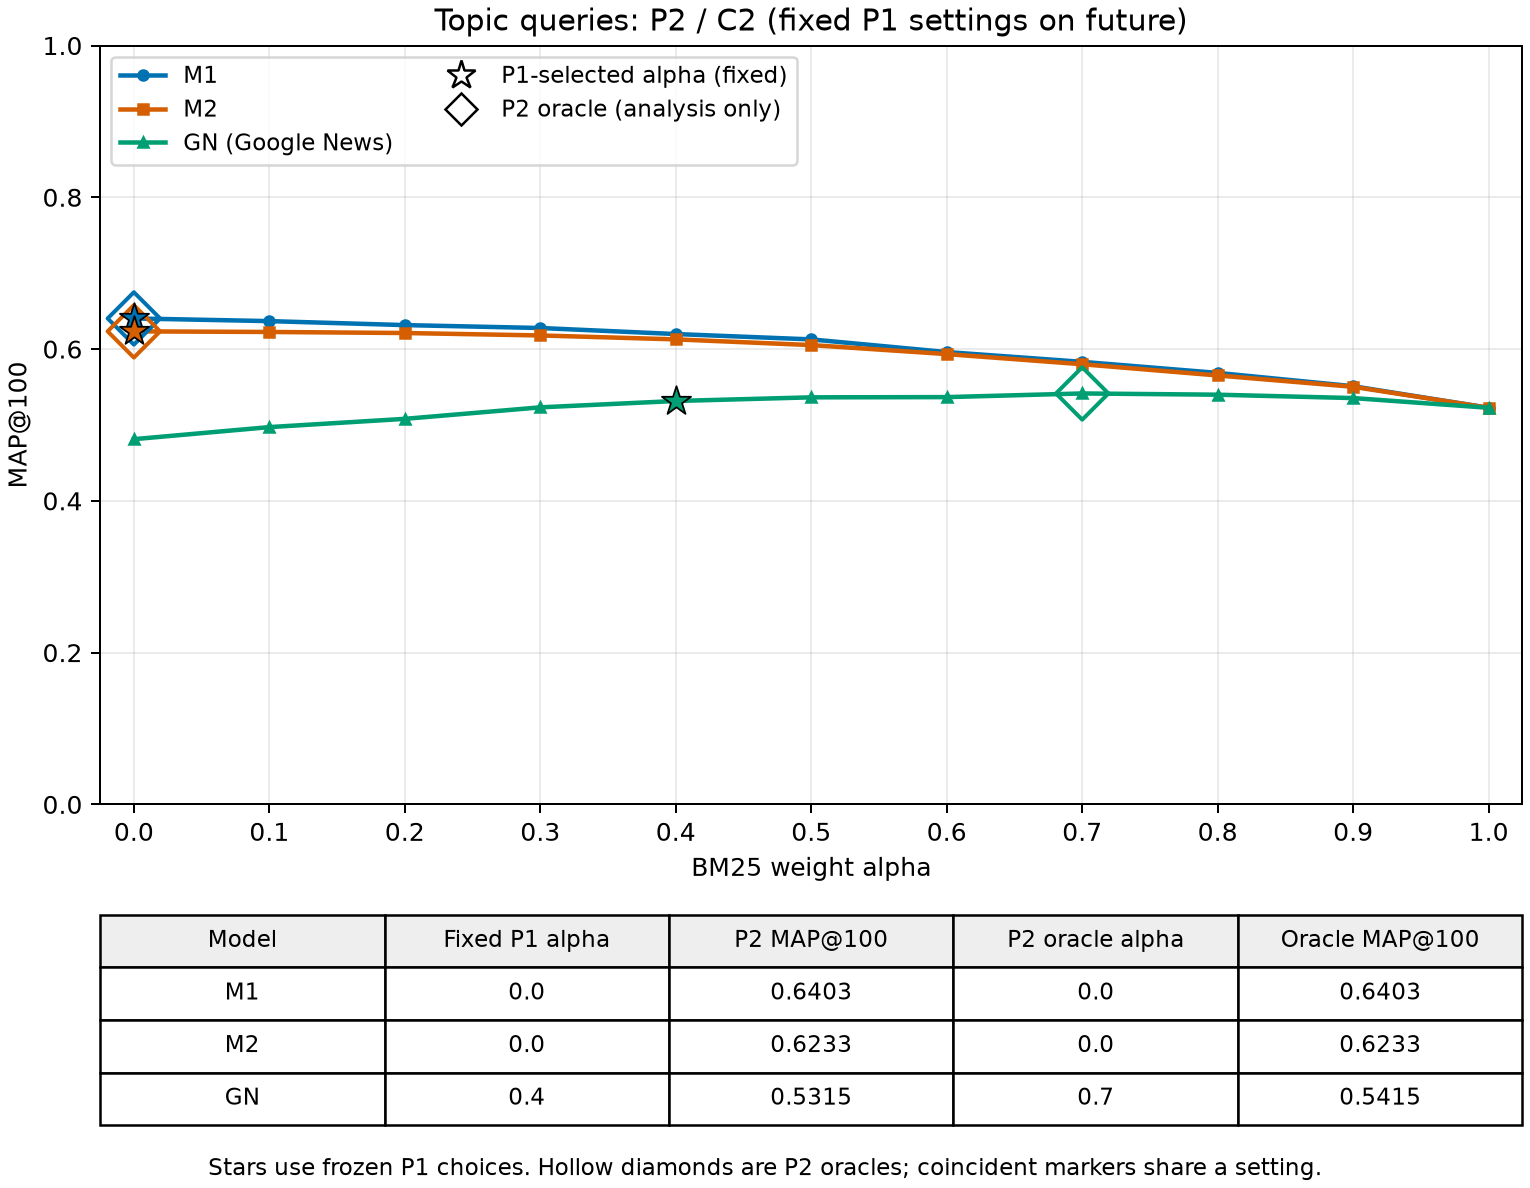

In [9]:
from IPython.display import Image, display

plots = [
    ("P1 — Known-item (MRR@10)", "part43_alpha_p1_known_item.png"),
    ("P2 — Known-item (MRR@10)", "part43_alpha_p2_known_item.png"),
    ("P1 — Topics (MAP@100)", "part43_alpha_p1_topics.png"),
    ("P2 — Topics (MAP@100)", "part43_alpha_p2_topics.png"),
]

for title, filename in plots:
    path = PART4 / filename
    assert path.exists(), f"Missing plot: {filename}"

    print("\n" + title)
    display(Image(filename=str(path), width=700))

#### 4.3 Key Findings

Parameter transfer varied across retrieval methods and query types.

For known-item queries, the P1-selected linear hybrid settings were α = 1.0 for M1 and M2, meaning that BM25 alone produced the best results. These settings also remained optimal on P2, with zero oracle gap.

For topic queries, M1 and M2 selected α = 0.0, favoring dense retrieval without BM25. These settings also transferred to P2 with zero oracle gap.

Query expansion showed less consistent transfer. Some parameter settings selected on P1 performed below the P2 oracle, indicating that the best expansion configuration can change across periods.

Overall, the results suggest that some hybrid fusion settings generalize across time, but query expansion parameters may require adjustment when applied to newer collections. The oracle comparisons describe the potential benefit of retuning rather than the performance of the frozen P1 configuration.

### 4.4 Temporal Generalisation

This experiment examines how embedding models perform across older (P1/C1) and newer (P2/C2) test collections.

The comparison includes BM25, dense retrieval using M1, M2, M2s, and GN, and query expansion using M1, M2, and GN.

Known-item performance is measured using MRR@10, while topic performance is measured using MAP@100. Query expansion uses the parameters selected on P1 without retuning on P2.

BM25 is included as a baseline because the two periods contain different queries and articles, making direct comparisons between periods sensitive to differences in test-set difficulty.

In [11]:
# Load saved Part 4.4 temporal comparison.

temporal = pd.read_csv(
    PART4 / "part44_temporal_comparison.csv"
)

methods = [
    "BM25",
    "Dense M1",
    "Dense M2",
    "Dense M2s",
    "Dense GN",
    "QE M1",
    "QE M2",
    "QE GN",
]

for query_type, metric in [
    ("known_item", "MRR@10"),
    ("topics", "MAP@100"),
]:
    table = temporal[
        temporal["query_type"] == query_type
    ].set_index("method").loc[methods].reset_index()

    columns = [
        "method",
        "P1_C1",
        "P2_C2",
        "change_P2_minus_P1",
        "minus_BM25_P1",
        "minus_BM25_P2",
    ]

    print(f"\n{query_type.upper()} — {metric}")
    display(table[columns].round(4))

print("Total methods:", len(methods))


KNOWN_ITEM — MRR@10


,method,P1_C1,P2_C2,change_P2_minus_P1,minus_BM25_P1,minus_BM25_P2
0,BM25,0.8293,0.6855,-0.1438,0.0000,0.0000
1,Dense M1,0.5667,0.4060,-0.1607,-0.2626,-0.2795
2,Dense M2,0.5734,0.4360,-0.1375,-0.2559,-0.2496
3,Dense M2s,0.5366,0.4186,-0.1181,-0.2927,-0.2670
4,Dense GN,0.5636,0.3944,-0.1693,-0.2657,-0.2912
5,QE M1,0.8281,0.6704,-0.1577,-0.0013,-0.0151
6,QE M2,0.8284,0.6534,-0.1750,-0.0009,-0.0321
7,QE GN,0.8315,0.6849,-0.1465,0.0021,-0.0006



TOPICS — MAP@100


,method,P1_C1,P2_C2,change_P2_minus_P1,minus_BM25_P1,minus_BM25_P2
0,BM25,0.4228,0.5226,0.0998,0.0000,0.0000
1,Dense M1,0.5597,0.6403,0.0807,0.1368,0.1177
2,Dense M2,0.5473,0.6233,0.0760,0.1245,0.1007
3,Dense M2s,0.5396,0.6267,0.0871,0.1167,0.1041
4,Dense GN,0.4576,0.4812,0.0237,0.0347,-0.0414
5,QE M1,0.5554,0.6022,0.0468,0.1326,0.0796
6,QE M2,0.5334,0.6447,0.1113,0.1105,0.1221
7,QE GN,0.4309,0.5008,0.0700,0.0080,-0.0218


Total methods: 8


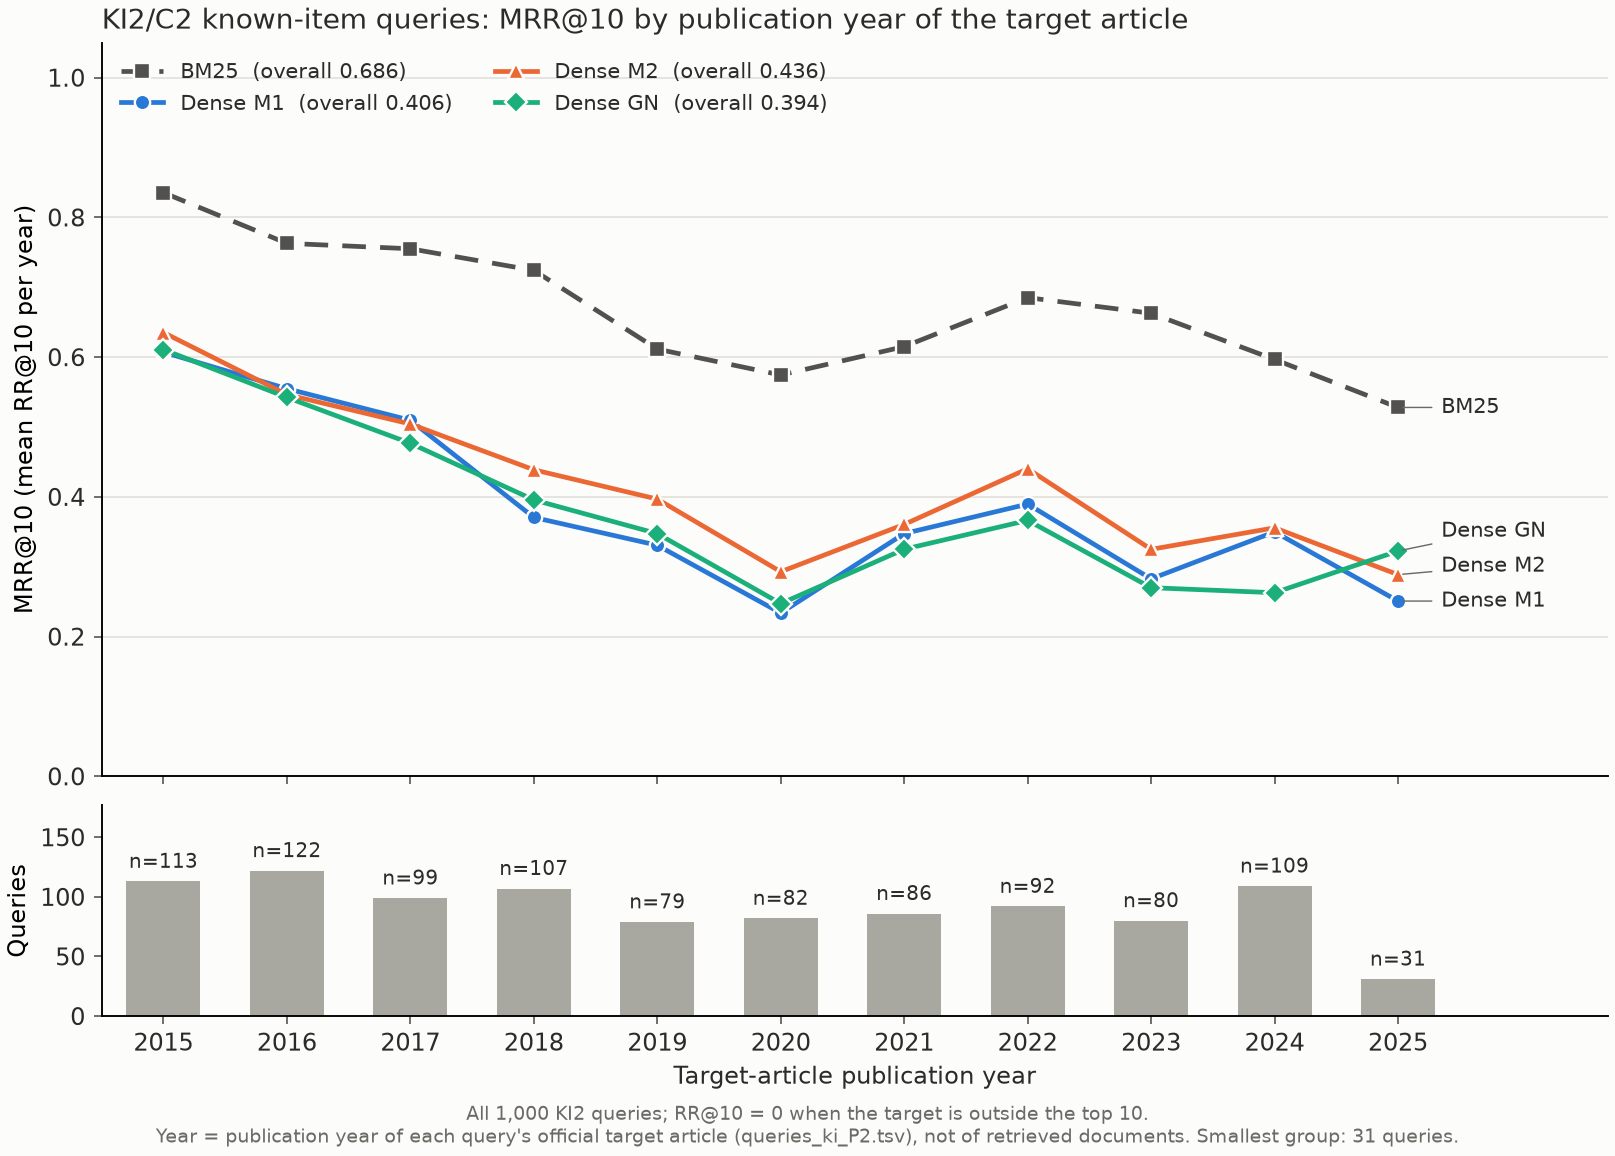

In [12]:
# Display saved KI2 MRR@10 by publication year.

from IPython.display import Image, display

year_plot = PART4 / "part44_ki2_mrr_by_year.png"

assert year_plot.exists(), "Missing Part 4.4 plot"

display(Image(filename=str(year_plot), width=800))

#### 4.4 Key Findings

**Performance across periods:** Known-item retrieval became more difficult on P2. BM25 MRR@10 decreased from 0.8293 on P1 to 0.6855 on P2. Topic retrieval showed the opposite pattern, with BM25 MAP@100 increasing from 0.4228 to 0.5226. These differences show why changes in embedding performance cannot be attributed to training period alone.

**Own-period performance:** Models trained on their matching period did not consistently outperform models trained on another period. Dense M1 achieved higher topic MAP@100 than M2s on both P1 and P2, although M2s performed slightly better than M1 on P2 known-item queries.

**Continued training (M2 versus M1):** On P1, M2 achieved slightly higher known-item MRR@10 (0.5734 versus 0.5667), but lower topic MAP@100 (0.5473 versus 0.5597). This indicates a small reduction in older-topic retrieval performance, but does not by itself establish significant forgetting.

**Continued training versus training from scratch:** M2 outperformed M2s on known-item retrieval in both periods. For topic retrieval, M2 was slightly better on P1, while M2s was slightly better on P2. Continued training therefore showed advantages for known-item retrieval, but not a consistent advantage across all tasks.

**Publication-year analysis:** The KI2 year-by-year graph compares BM25 with Dense M1, M2, and GN from 2015 through 2025. BM25 performed better than the dense models across the publication years, supporting its advantage for exact known-item retrieval.

Overall, the results do not establish a universal benefit from training embeddings on the same period as the test collection. Model effectiveness depends on query type, training history, and test-set difficulty.

### 4.5 Per-Query Analysis

This section examines individual queries to understand when updating embeddings improves or reduces retrieval effectiveness.

Four analyses are performed:

- **(a) New vocabulary:** Compare Dense M1 and Dense M2 on KI2 queries containing words available only in M2.
- **(b) Semantic drift:** Examine queries containing words identified as highly drifted in Part 2.
- **(c) Topic queries:** Compare BM25, QE M1, and QE M2 on all 32 C2 topics and examine expansion terms.
- **(d) Hybrid retrieval:** Examine three known-item queries where hybrid retrieval beats BM25 and three where it performs worse.

The analysis uses saved per-query results and paired randomization tests.

In [13]:
# 4.5(a): New vocabulary analysis

with (PART4 / "part45_summary.json").open(encoding="utf-8") as f:
    part45 = json.load(f)

assert part45["all_complete"], "Part 4.5 results are incomplete"

new_vocab = pd.read_csv(PART4 / "part45a_new_vocab_queries.csv")
subset_tests = pd.read_csv(PART4 / "part45a_subset_tests.csv")

print("M2-only vocabulary words:", part45["vocabulary"]["M2_only"])
print("KI2 queries containing these words:",
      part45["a_new_vocabulary"]["matching_queries"])
print("Percentage of KI2 queries:",
      f"{part45['a_new_vocabulary']['percentage']:.1f}%")

print("\nM1 versus M2: subset and remaining queries")
display(subset_tests[
    ["group", "queries", "baseline_mean", "method_mean",
     "mean_difference", "p_value", "significant",
     "improved", "worse", "tied"]
].round(4))

example_cols = [
    "query", "new_words", "dense_m1_rank", "dense_m2_rank",
    "rr10_change_m2_minus_m1"
]

print("\nThree examples where M2 improves retrieval:")
display(
    new_vocab.sort_values(
        "rr10_change_m2_minus_m1", ascending=False
    )[example_cols].head(3)
)

print("\nThree examples where M2 performs worse:")
display(
    new_vocab.sort_values(
        "rr10_change_m2_minus_m1"
    )[example_cols].head(3)
)

M2-only vocabulary words: 4966
KI2 queries containing these words: 112
Percentage of KI2 queries: 11.2%

M1 versus M2: subset and remaining queries


,group,queries,baseline_mean,method_mean,mean_difference,p_value,significant,improved,worse,tied
0,subset,112,0.2458,0.4413,0.1955,0.000,True,45,6,61
1,remainder,888,0.4262,0.4353,0.0091,0.288,False,159,135,594



Three examples where M2 improves retrieval:


,query,new_words,dense_m1_rank,dense_m2_rank,rr10_change_m2_minus_m1
39,kaitlyn greenidge libertie,greenidge,NaN,1.0,1.0
23,senegal elections macky sall,macky sall,72.0,1.0,1.0
71,aditi banga jonathan schwartz,banga,15.0,1.0,1.0



Three examples where M2 performs worse:


,query,new_words,dense_m1_rank,dense_m2_rank,rr10_change_m2_minus_m1
10,trump evan gershkovich putin,gershkovich,1.0,12.0,-1.00
77,real estate sales coronavirus pandemic nervous...,coronavirus,2.0,4.0,-0.25
84,germanwings pilot safety aviation eu,germanwings,4.0,47.0,-0.25


In [14]:
# 4.5(b): Semantic drift and retrieval

drift_groups = pd.read_csv(PART4 / "part45b_drift_groups.csv")
drift_queries = pd.read_csv(PART4 / "part45b_drift_queries.csv")

drift_words = part45["findings"]["b_semantic_drift"][
    "most_drifted_words_from_part2"
]

print("Most-drifted words from Part 2:")
print(", ".join(drift_words))

print("\nKI2/C2: M1 versus M2 across drift groups")

ki2_groups = drift_groups[
    drift_groups["test_set"] == "KI2/C2"
]

display(ki2_groups[
    ["group_definition", "group", "queries",
     "baseline_mean", "method_mean", "mean_difference",
     "p_value", "significant", "small_group"]
].round(4))

ki2_drift = drift_queries[
    drift_queries["test_set"] == "KI2/C2"
]

example_cols = [
    "query", "drifted_words", "dense_m1_rank",
    "dense_m2_rank", "rr10_change_m2_minus_m1"
]

print("\nExamples where M2 improves:")
display(
    ki2_drift.sort_values(
        "rr10_change_m2_minus_m1", ascending=False
    )[example_cols].head(3)
)

print("\nExamples where M2 performs worse:")
display(
    ki2_drift.sort_values(
        "rr10_change_m2_minus_m1"
    )[example_cols].head(3)
)

Most-drifted words from Part 2:
pence, trump, distancing, zoom, ai

KI2/C2: M1 versus M2 across drift groups


,group_definition,group,queries,baseline_mean,method_mean,mean_difference,p_value,significant,small_group
16,drifted_any,subset,78,0.2775,0.2543,-0.0231,0.4860,False,False
17,drifted_any,remainder,922,0.4169,0.4513,0.0345,0.0000,True,False
18,stable_control_any,subset,27,0.3056,0.3173,0.0117,0.8343,False,True
19,stable_control_any,remainder,973,0.4088,0.4392,0.0305,0.0006,True,False
20,drifted_excluding_M2_only_vocab,subset,73,0.2828,0.2649,-0.0179,0.5684,False,False
21,drifted_excluding_M2_only_vocab,remainder,927,0.4157,0.4494,0.0337,0.0001,True,False
22,drifted_word:pence,subset,1,0.0000,0.2000,0.2000,1.0000,False,True
23,drifted_word:pence,remainder,999,0.4064,0.4362,0.0298,0.0010,True,False
24,drifted_word:trump,subset,74,0.2790,0.2451,-0.0338,0.3086,False,False
25,drifted_word:trump,remainder,926,0.4161,0.4512,0.0351,0.0000,True,False



Examples where M2 improves:


,query,drifted_words,dense_m1_rank,dense_m2_rank,rr10_change_m2_minus_m1
36,escort anastasia vashukevich nastya rybka trump,trump,93.0,1.0,1.000000
29,pam bondi trump attorney general,trump,3.0,1.0,0.666667
77,jan report hutchinson trump ornato suv,trump,3.0,1.0,0.666667



Examples where M2 performs worse:


,query,drifted_words,dense_m1_rank,dense_m2_rank,rr10_change_m2_minus_m1
11,trump evan gershkovich putin,trump,1.0,12.0,-1.000000
59,kamala harris mcdonalds work trump,trump,1.0,100.0,-1.000000
32,donald trump roy cohn,trump,1.0,3.0,-0.666667


In [17]:
# 4.5(c): Per-topic AP@100 and expansion terms

topic_ap = pd.read_csv(
    PART4 / "part45c_topic_ap.csv",
    dtype={"tid": str}
)

expansion = pd.read_csv(
    PART4 / "part45c_expansion_terms.csv",
    dtype={"tid": str}
)

print("C2: Per-topic AP@100 for all 32 topics")

display(topic_ap[
    ["tid", "query", "AP@100 BM25",
     "AP@100 QE M1", "AP@100 QE M2",
     "delta_QE_M2_minus_QE_M1"]
].round(4))

helped = topic_ap.nlargest(
    3, "delta_QE_M2_minus_QE_M1"
)

hurt = topic_ap.nsmallest(
    3, "delta_QE_M2_minus_QE_M1"
)

print("\nThree topics where QE M2 helps most:")
display(helped.round(4))

print("\nThree topics where QE M2 hurts most:")
display(hurt.round(4))

# Explain all six using their actual saved expansion terms.

topic_notes = {
    item["tid"]: item
    for item in part45["findings"]["c_topics"]["topics"]
}

for _, topic in pd.concat([helped, hurt]).iterrows():
    tid = topic["tid"]

    print(f"\n{'=' * 55}")
    print(f"{tid}: {topic['query']}")
    print(
        f"QE M2 - QE M1 AP@100: "
        f"{topic['delta_QE_M2_minus_QE_M1']:+.4f}"
    )

    for model in ["M1", "M2"]:
        terms = expansion[
            (expansion["tid"] == tid) &
            (expansion["model"] == f"QE {model}")
        ].sort_values("rank")

        print(f"\nQE {model} expansion terms:")
        print(", ".join(terms["term"].head(8).tolist()))

    if tid in topic_notes:
        print("\nInterpretation:")
        print(topic_notes[tid]["interpretation"])

C2: Per-topic AP@100 for all 32 topics


,tid,query,AP@100 BM25,AP@100 QE M1,AP@100 QE M2,delta_QE_M2_minus_QE_M1
0,T01,africa,0.4045,0.7722,0.8273,0.0551
1,T02,art,0.8685,0.9099,0.9414,0.0315
2,T03,asia,0.3277,0.4135,0.3583,-0.0552
3,T04,baseball,0.7165,0.9879,0.9714,-0.0165
4,T05,basketball,0.3317,0.4670,0.4352,-0.0318
5,T06,books,0.8290,0.6252,0.8709,0.2457
6,T07,dance,0.9180,0.9410,0.9668,0.0258
7,T08,economy,0.3056,0.5544,0.6448,0.0903
8,T09,europe,0.3494,0.8059,0.9842,0.1784
9,T10,fashion,0.8858,0.8151,0.8432,0.0281



Three topics where QE M2 helps most:


,tid,query,AP@100 BM25,AP@100 QE M1,AP@100 QE M2,relevant_documents,delta_QE_M2_minus_QE_M1,role
22,T23,politics,0.9306,0.3011,0.9887,38673,0.6876,helped
19,T20,music,0.4803,0.6018,0.9212,8588,0.3194,helped
10,T11,food,0.2027,0.2286,0.5021,8210,0.2736,helped



Three topics where QE M2 hurts most:


,tid,query,AP@100 BM25,AP@100 QE M1,AP@100 QE M2,relevant_documents,delta_QE_M2_minus_QE_M1,role
11,T12,football,0.7341,0.9553,0.5599,2975,-0.3953,hurt
18,T19,movies,0.2815,0.7859,0.3989,6282,-0.3870,hurt
23,T24,real estate,0.6910,0.6928,0.5583,7272,-0.1345,hurt



T23: politics
QE M2 - QE M1 AP@100: +0.6876

QE M1 expansion terms:
lawmaking, political, rightward, polarization, politicians, discourse, leftward, doctrinaire

QE M2 expansion terms:
lerer, corasaniti, tribalism, crosscurrents, centrism, cronyism, political, evangelicalism

Interpretation:
Consistent with the AP change: M2-only precise terms: lerer (df 249, 100% relevant), corasaniti (df 40, 100% relevant), divisiveness (df 10, 80% relevant), russonello (df 17, 88% relevant). Counter-evidence: M2-only noisy terms: culture (df 2061, 8% relevant).

T20: music
QE M2 - QE M1 AP@100: +0.3194

QE M1 expansion terms:
edm, classical, electronica, rdio, songs, jazz, afrobeat, synthesizer

QE M2 expansion terms:
classical, electronica, jazz, sugarland, mannes, arvo, danceafrica, edm

Interpretation:
Consistent with the AP change: M2-only precise terms: andris (df 17, 100% relevant). Counter-evidence: M1-only precise terms: synthesizer (df 18, 89% relevant), mixtapes (df 11, 100% relevant), mu

In [16]:
# 4.5(d): Three hybrid wins and three hybrid losses

hybrid_examples = pd.read_csv(
    PART4 / "part45d_hybrid_examples.csv"
)

hybrid_info = part45["findings"]["d_hybrid"]

print("Collection:", hybrid_info["collection"])
print("Dense model:", hybrid_info["model"])
print("Illustrative hybrid alpha:", hybrid_info["alpha"])

print("\nNote:", hybrid_info["why_not_p1_selected"])

columns = [
    "outcome", "query", "bm25_rank",
    "dense_rank", "hybrid_rank",
    "rr10_change_hybrid_minus_bm25"
]

print("\nHybrid retrieval examples:")
display(hybrid_examples[columns].round(4))

for _, row in hybrid_examples.iterrows():
    print("\n" + "=" * 60)
    print("Outcome:", row["outcome"])
    print("Query:", row["query"])
    print("BM25 rank:", row["bm25_rank"])
    print("Dense rank:", row["dense_rank"])
    print("Hybrid rank:", row["hybrid_rank"])
    print("\nExplanation:")
    print(row["explanation"])

Collection: C2
Dense model: M2
Illustrative hybrid alpha: 0.5

Note: P1-selected known-item alpha=1.0 reproduces BM25 exactly, so it has no wins or losses

Hybrid retrieval examples:


,outcome,query,bm25_rank,dense_rank,hybrid_rank,rr10_change_hybrid_minus_bm25
0,hybrid_beats_BM25,israel hamas ceasefire proposal,4,4.0,1,0.7500
1,hybrid_beats_BM25,pam bondi trump attorney general,3,1.0,1,0.6667
2,hybrid_beats_BM25,indian food wine pairings,3,3.0,1,0.6667
3,hybrid_loses_to_BM25,jimmy fallon trump turkey pardoning,1,NaN,15,-1.0000
4,hybrid_loses_to_BM25,harry potter tiktok,1,59.0,23,-1.0000
5,hybrid_loses_to_BM25,global antitrust institute google amazon qualcomm,1,NaN,26,-1.0000



Outcome: hybrid_beats_BM25
Query: israel hamas ceasefire proposal
BM25 rank: 4
Dense rank: 4.0
Hybrid rank: 1

Explanation:
Target C2-191415 (BM25 rank 4, dense M2 rank 4) has normalized BM25 0.965 and dense 0.967, fused 0.966 -> hybrid rank 1. The BM25 top document C2-194436 has normalized BM25 1.000, dense 0.745, fused 0.872. Query terms matched: target 3/4, BM25 top document 3/4. Fusion helped: against the BM25 top document, the target's dense advantage (+0.222) outweighs its BM25 shortfall (-0.035) at alpha=0.5 (0.5 x -0.035 + 0.5 x +0.222 = +0.094).

Outcome: hybrid_beats_BM25
Query: pam bondi trump attorney general
BM25 rank: 3
Dense rank: 1.0
Hybrid rank: 1

Explanation:
Target C2-201870 (BM25 rank 3, dense M2 rank 1) has normalized BM25 0.942 and dense 1.000, fused 0.971 -> hybrid rank 1. The BM25 top document C2-208014 has normalized BM25 1.000, dense 0.772, fused 0.886. Query terms matched: target 5/5, BM25 top document 5/5. Fusion helped: against the BM25 top document, the 

#### 4.5 Key Findings

**(a) New vocabulary:** Of the 1,000 KI2 queries, 112 (11.2%) contained at least one word present in M2 but missing from M1. On this subset, Dense M2 achieved MRR@10 of 0.4413 compared with 0.2458 for Dense M1, an improvement of 0.1955 (p < 0.0001). On the remaining 888 queries, the difference was only 0.0091 and was not statistically significant (p = 0.288). This indicates that M2's vocabulary expansion contributed substantially to its improvements on affected queries.

**(b) Semantic drift:** The drifted-word subset contained 78 KI2 queries, most involving "trump." M2 performed slightly worse than M1 on this subset (MRR@10 difference = -0.0231, p = 0.486). This does not provide significant evidence that updated word meanings improved retrieval. The small and uneven word groups limit broader conclusions.

**(c) Topic queries:** QE M2 produced its largest improvements over QE M1 for Politics, Music, and Food. Its largest declines occurred for Football, Movies, and Real Estate. The actual expansion terms show how different embedding models introduce different vocabulary into the same topic query. Some terms are useful for identifying relevant articles, while others introduce less relevant associations. Therefore, updated embeddings do not consistently improve query expansion.

**(d) Hybrid retrieval:** The illustrative hybrid setting (BM25 + Dense M2, α = 0.5) improved three known-item rankings by raising the relevance of the correct documents through semantic similarity. It also worsened three rankings where dense retrieval gave less support to the correct document. These examples demonstrate that hybrid fusion can either correct or disrupt BM25's ranking depending on the query.

Overall, the per-query analysis shows that updated embeddings are particularly useful when newer vocabulary is missing from the older model. However, improvements from semantic drift, query expansion, and hybrid retrieval are less consistent and depend on individual query characteristics.